# Energy transfer and flux across ten realizations

Source: `data/3D/energy_flux_N=1024_realizations=10.xlsx`, sheets `run1` through `run10`.
The workbook is read without modification. Styling follows `plot_energy_flux.ipynb`
and the original `setup_plot.py`, including the 4:3 panel aspect ratio, logarithmic
horizontal axes, linear vertical axes, thin frames, and faint grid lines.
The canvas is 17.9 cm wide and 6.9 cm high, with 8 pt text.

Each panel contains one blue line representing the arithmetic mean over the ten
realizations at each common wavenumber. The gray region is the pointwise mean
plus or minus one **sample standard deviation** (`ddof=1`). It describes variability
across realizations, rather than the standard error or a confidence interval.
The complete signed band is shown; negative values are retained. No smoothing,
absolute-value transformation, or additional normalization is applied.

Run the four code cells in order. Dependencies: NumPy, pandas, openpyxl, Matplotlib,
and the LaTeX installation used by `setup_plot.py`.


In [9]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter

PROJECT_ROOT = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "setup_plot.py").is_file()
     and (directory / "data/3D/energy_flux_N=1024_realizations=10.xlsx").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the QuanEncodeTurb project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from setup_plot import setup_plot

setup_plot(fontsize=8, fonttype="sans-serif", dpi=150)
fontsize = 8
mpl.rcParams.update({
    "axes.labelsize": fontsize,
    "xtick.labelsize": fontsize,
    "ytick.labelsize": fontsize,
    "legend.fontsize": fontsize,
    "savefig.bbox": None,
})

DATA_PATH = PROJECT_ROOT / "data/3D/energy_flux_N=1024_realizations=10.xlsx"
OUTPUT_DIR = PROJECT_ROOT / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_WIDTH_CM = 15
FIGURE_HEIGHT_CM = 6.9
EXPORT_DPI = 600


In [10]:
# All ten realizations receive equal weight at each common wavenumber.
run_names = [f"run{i}" for i in range(1, 11)]
sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine="openpyxl")
if set(sheets) != set(run_names):
    raise ValueError(f"Expected sheets run1 to run10; found {list(sheets)}")

columns = ["k", "transfer", "energy_flux"]
k_flux = sheets[run_names[0]]["k"].to_numpy(dtype=float)
if not np.isfinite(k_flux).all() or not np.all(np.diff(k_flux) > 0):
    raise ValueError("Wavenumbers must be finite and strictly increasing.")
if not np.all(k_flux > 0):
    raise ValueError("Logarithmic wavenumber axes require k > 0.")

realizations = []
for name in run_names:
    frame = sheets[name]
    if list(frame.columns) != columns:
        raise ValueError(f"Unexpected columns in {name}: {list(frame.columns)}")
    if not np.array_equal(frame["k"].to_numpy(dtype=float), k_flux):
        raise ValueError(f"Wavenumber grid in {name} differs from run1.")
    values = frame[["transfer", "energy_flux"]].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"Nonfinite transfer or energy-flux data in {name}.")
    realizations.append(values)

# Shape: (realization, wavenumber, variable).
realizations = np.stack(realizations, axis=0)
n_realizations = realizations.shape[0]
mean = realizations.mean(axis=0)
std = realizations.std(axis=0, ddof=1)
transfer_mean, energy_flux_mean = mean.T
transfer_std, energy_flux_std = std.T

print(f"Loaded {n_realizations} realizations; {len(k_flux)} common wavenumbers.")
print(f"Wavenumber interval: [{k_flux[0]:g}, {k_flux[-1]:g}]")
print("Gray bands: pointwise mean +/- sample standard deviation (ddof=1).")


Loaded 10 realizations; 341 common wavenumbers.
Wavenumber interval: [1, 341]
Gray bands: pointwise mean +/- sample standard deviation (ddof=1).


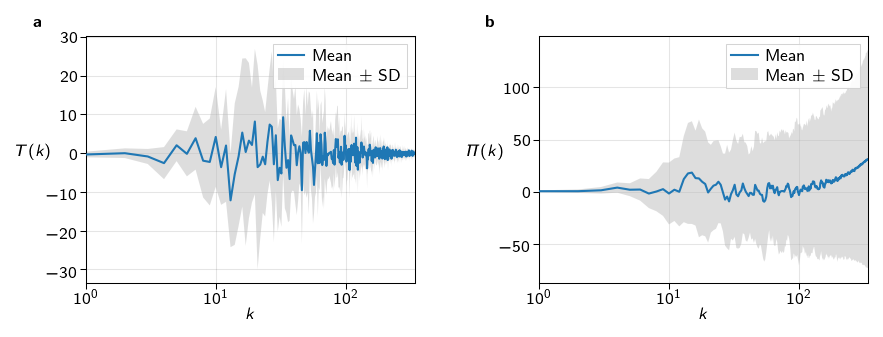

In [12]:
fig = plt.figure(figsize=(FIGURE_WIDTH_CM / 2.54, FIGURE_HEIGHT_CM / 2.54))

# Keep the 4:3 panel aspect ratio of plot_energy_flux.ipynb.
left_cm = 1.4
right_cm = 0.35
gap_cm = 2.1
bottom_cm = 1.05
axes_width_cm = (FIGURE_WIDTH_CM - left_cm - right_cm - gap_cm) / 2
axes_height_cm = axes_width_cm * 3 / 4

line_color = "#1f77b4"  # Same default blue as the original notebook.
shade_color = "#BDBDBD"
shade_alpha = 0.5
axes = []

for index, (mean_values, std_values, ylabel) in enumerate([
    (transfer_mean, transfer_std, r"$T(k)$"),
    (energy_flux_mean, energy_flux_std, r"$\varPi(k)$"),
]):
    ax = fig.add_axes([
        (left_cm + index * (axes_width_cm + gap_cm)) / FIGURE_WIDTH_CM,
        bottom_cm / FIGURE_HEIGHT_CM,
        axes_width_cm / FIGURE_WIDTH_CM,
        axes_height_cm / FIGURE_HEIGHT_CM,
    ])
    axes.append(ax)
    ax.grid(color="k", linestyle="-", linewidth=0.5, alpha=0.1)
    ax.set_axisbelow(True)
    ax.set_xscale("log")

    # Keep the complete signed band, including portions below zero.
    lower = mean_values - std_values
    upper = mean_values + std_values
    ax.fill_between(
        k_flux, lower, upper,
        color=shade_color, alpha=shade_alpha,
        linewidth=0, edgecolor="none", zorder=1,
    )
    line, = ax.plot(
        k_flux, mean_values,
        color=line_color, linewidth=1, linestyle="-", zorder=3,
        label="Mean",
    )

    # Y limits contain the complete mean +/- SD envelope.
    low = float(lower.min())
    high = float(upper.max())
    padding = 0.06 * (high - low)
    if padding == 0:
        padding = max(abs(low), 1.0) * 0.06
    ax.set_ylim(low - padding, high + padding)
    ax.set_xlim(1, k_flux[-1])
    ax.set_xlabel(r"$k$", labelpad=0, fontsize=fontsize)
    ax.set_ylabel(ylabel, rotation=0, labelpad=6, fontsize=fontsize)
    ax.xaxis.set_minor_formatter(NullFormatter())

    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.tick_params(
        axis="x", which="major", direction="out", top=False, right=False,
        length=3, width=0.5, pad=1.5,
    )
    ax.tick_params(
        axis="y", which="major", direction="out", top=False, right=False,
        length=3, width=0.5, pad=1,
    )
    ax.tick_params(
        which="minor", direction="out", top=False, right=False,
        length=0, width=0.5,
    )
    ax.text(
        -0.16, 1.025, rf"\textbf{{{'ab'[index]}}}",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=fontsize,
    )
    leg = ax.legend(
        handles=[line, Patch(facecolor=shade_color, alpha=shade_alpha,
                             edgecolor="none", label=r"Mean $\pm$ SD")],
        loc="upper right", frameon=True, fancybox=False,
        framealpha=0.9, edgecolor="#D0D0D0", fontsize=fontsize,
        borderpad=0.3, labelspacing=0.25, handlelength=1.6, handletextpad=0.5,
    )
    leg.get_frame().set_linewidth(0.5)

    assert np.all(lower <= mean_values) and np.all(mean_values <= upper)
    assert len(ax.lines) == 1

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for index, ax in enumerate(axes):
    bounds = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted())
    if bounds.x0 < 0 or bounds.y0 < 0 or bounds.x1 > 1 or bounds.y1 > 1:
        raise RuntimeError(f"Panel {index + 1} extends outside the canvas: {bounds}")

# 
fig.savefig(OUTPUT_DIR / "energy_flux.pdf", transparent=True, orientation='portrait', format='pdf', bbox_inches='tight')
